# U-net+V3: ColonDB单源跨数据集Raw与99.5%+FMM实验

仅使用CVC-ColonDB训练，并在CVC-300、CVC-ClinicDB、ETIS-LaribPolypDB和Kvasir上直接测试。Raw与FMM使用固定种子42生成的同一组304/76训练/验证划分，并分别训练独立模型。


In [1]:
# 基础环境与依赖
import os
os.environ.setdefault("SM_FRAMEWORK", "tf.keras")

import h5py
import gc
import math
import re
from pathlib import Path

import cv2
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, AveragePooling2D, Conv2DTranspose,
    BatchNormalization, Activation, ReLU, UpSampling2D, Concatenate,
    Dropout, LeakyReLU, concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2
from tensorflow.keras.initializers import he_normal

import segmentation_models as sm
sm.set_framework('tf.keras')


Segmentation Models: using `tf.keras` framework.


In [2]:
# =========================
# 运行配置
# =========================
MODEL_NAME = 'U-net+V3'
MODEL_DIR_NAME = 'U-net+V3'

# 本跨数据集实验依次独立训练Raw与FMM模型，再读取各自最佳权重评估。
RUN_TRAINING = True

# 训练保存与推理读取统一使用固定文件名：
# 模型名称_img_bestweight.h5
# 模型名称_99.5+FMM_bestweight.h5

IMAGE_HEIGHT = 288
IMAGE_WIDTH = 384
IMAGE_SIZE = (IMAGE_WIDTH, IMAGE_HEIGHT)
PERCENTILE = 99.5
INPAINT_RADIUS = 10
JPEG_QUALITY = 95
PREDICTION_THRESHOLD = 0.5
BOUNDARY_DILATION_RATIO = 0.02

EPOCHS = 300
TRAIN_BATCH_SIZE = 8
# 与原Notebook的model.evaluate默认值一致；表格与可视化共用该次批量前向缓存。
INFERENCE_BATCH_SIZE = 8
# 原Notebook的model.evaluate未指定batch_size，Keras 2.9默认按32张分组计算指标。
METRIC_BATCH_SIZE = 32
SEED = 42

LOAD_BY_NAME = False  # 仅保留为说明；实际始终严格完整载入
USE_SM_TRAINING_LOSS = True
USE_SM_EVALUATION_IOU = True

# 可视化选择必须在评估前设置，便于缓存同一次前向的对应样本。
VIS_DATASET = "ETIS-LaribPolypDB"
VIS_SAMPLE_INDEX = 48

SOURCE_DATASET = "CVC-ColonDB"
EXPECTED_SOURCE_COUNT = 380
EXPECTED_TRAIN_COUNT = 304
EXPECTED_VAL_COUNT = 76

TEST_DATASETS = [
    "CVC-300",
    "CVC-ClinicDB",
    "ETIS-LaribPolypDB",
    "Kvasir",
]
EXPECTED_TEST_COUNTS = {
    "CVC-300": 60,
    "CVC-ClinicDB": 62,
    "ETIS-LaribPolypDB": 196,
    "Kvasir": 100,
}


## 模型结构（复制自原Notebook）


In [3]:
def build_model():
    BACKBONE = 'inceptionv3'
    return sm.Unet(
        BACKBONE, encoder_weights='imagenet' if RUN_TRAINING else None
    )


In [4]:
# =========================
# 损失函数与原评价指标
# =========================
def bce_jaccard_loss(y_true, y_pred, smooth=1e-7, alpha=0.5):
    bce = tf.keras.losses.binary_crossentropy(y_true, y_pred)
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f + y_pred_f) - intersection
    jaccard = (intersection + smooth) / (union + smooth)
    jaccard_loss = 1 - jaccard
    return alpha * bce + (1 - alpha) * jaccard_loss


def dice_score(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    denominator = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    return (2.0 * intersection + smooth) / (denominator + smooth)


def iou_score(y_true, y_pred, smooth=1e-7):
    y_true_f = tf.keras.backend.flatten(y_true)
    y_pred_f = tf.keras.backend.flatten(y_pred)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)


def compile_for_training(model):
    if USE_SM_TRAINING_LOSS:
        model.compile(
            optimizer='Adam',
            loss=sm.losses.bce_jaccard_loss,
            metrics=[sm.metrics.iou_score],
        )
    else:
        model.compile(
            optimizer='Adam',
            loss=bce_jaccard_loss,
            metrics=[iou_score],
        )
    return model


def compile_for_evaluation(model):
    # 严格沿用原Notebook最终历史权重评价时选择的IoU定义。
    evaluation_iou = sm.metrics.iou_score if USE_SM_EVALUATION_IOU else iou_score
    model.compile(
        optimizer='Adam',
        loss=bce_jaccard_loss,
        metrics=[dice_score, evaluation_iou],
    )
    return model


In [5]:
# =========================
# 项目路径、Raw/FMM处理与文件夹数据流
# =========================
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


PROJECT_ROOT = Path("D:\WJY\paper1")
DATA_ROOT = PROJECT_ROOT / "data"
TEST_DATA_ROOT = DATA_ROOT / "Test"
SOURCE_DATASET_DIR = TEST_DATA_ROOT / SOURCE_DATASET
TRAIN_IMAGE_DIR = SOURCE_DATASET_DIR / "img"
TRAIN_MASK_DIR = SOURCE_DATASET_DIR / "masks"
# Jupyter内核从Notebook所在目录启动时，Path.cwd()即Notebook目录。
NOTEBOOK_DIR = Path.cwd().resolve()
OUTPUT_ROOT = NOTEBOOK_DIR / "U-net+V3-ColonDB-CrossDataset-Outputs"
WEIGHT_MODEL_DIR = OUTPUT_ROOT / "weights"
RESULTS_MODEL_DIR = OUTPUT_ROOT / "results"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("MODEL:", MODEL_NAME)


def list_image_names(image_dir):
    # 保留历史H5制作时的os.listdir顺序；同名配对避免图像与mask错位。
    names = [
        name for name in os.listdir(image_dir)
        if (Path(image_dir) / name).is_file() and Path(name).suffix.lower() in IMAGE_EXTENSIONS
    ]
    if not names:
        raise FileNotFoundError(f"图像目录为空: {image_dir}")
    return names


def validate_pairs(image_dir, mask_dir, names):
    image_names = set(names)
    mask_names = set(list_image_names(mask_dir))
    missing = sorted(image_names - mask_names)
    unexpected = sorted(mask_names - image_names)
    if missing:
        raise FileNotFoundError(
            f"{mask_dir}缺少{len(missing)}个同名mask，例如: {missing[:5]}"
        )
    if unexpected:
        raise ValueError(
            f"{mask_dir}包含{len(unexpected)}个无同名图像的mask，例如: {unexpected[:5]}"
        )


def validate_dataset_directory(dataset_name, expected_count):
    dataset_dir = TEST_DATA_ROOT / dataset_name
    image_dir = dataset_dir / "img"
    mask_dir = dataset_dir / "masks"
    names = sorted(list_image_names(image_dir))
    validate_pairs(image_dir, mask_dir, names)
    if len(names) != expected_count:
        raise ValueError(
            f"{dataset_name}应有{expected_count}组图像和mask，实际为{len(names)}组"
        )
    return names


def read_raw_image(image_path):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f"无法读取图像: {image_path}")
    image = cv2.resize(image, IMAGE_SIZE)
    # 历史H5制作流程在OpenCV读取后执行[..., ::-1]，模型实际使用RGB输入。
    image = image[..., ::-1]
    return image.astype(np.float32) / 255.0


def create_highlight_mask(image_path, percentile=PERCENTILE):
    gray = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise ValueError(f"无法读取灰度图: {image_path}")
    threshold = np.percentile(gray, percentile)
    _, highlight_mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    return highlight_mask


def read_fmm_image(image_path):
    # 严格沿用原高光修复代码：99.5%阈值mask + 0.6倍缩放 + TELEA/FMM半径10。
    src = cv2.imread(str(image_path))
    if src is None:
        raise ValueError(f"无法读取图像: {image_path}")
    highlight_mask = create_highlight_mask(image_path)

    resized_src = cv2.resize(
        src, None, fx=0.6, fy=0.6, interpolation=cv2.INTER_CUBIC
    )
    resized_highlight_mask = cv2.resize(
        highlight_mask, None, fx=0.6, fy=0.6, interpolation=cv2.INTER_CUBIC
    )
    restored = cv2.inpaint(
        resized_src, resized_highlight_mask, INPAINT_RADIUS, cv2.INPAINT_TELEA
    )
    restored = cv2.resize(restored, IMAGE_SIZE)

    # 原流程将修复结果保存为JPG后再读取。这里在内存中模拟相同JPG往返，不产生中间文件。
    ok, encoded = cv2.imencode(
        ".jpg", restored, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY]
    )
    if not ok:
        raise RuntimeError(f"FMM结果JPG编码失败: {image_path}")
    restored = cv2.imdecode(encoded, cv2.IMREAD_COLOR)
    # 与历史FMM-H5保持一致：JPG重新读取后由BGR转换为RGB。
    restored = restored[..., ::-1]
    return restored.astype(np.float32) / 255.0


def read_segmentation_mask(mask_path):
    mask = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"无法读取mask: {mask_path}")
    mask = cv2.resize(mask, IMAGE_SIZE)
    return (mask / 255).reshape(IMAGE_HEIGHT, IMAGE_WIDTH, 1)


class FolderSegmentationSequence(keras.utils.Sequence):
    def __init__(
        self, image_dir, mask_dir, names, indexes, batch_size,
        condition="raw", shuffle=False, seed=SEED
    ):
        super().__init__()
        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.names = list(names)
        self.indexes = np.asarray(indexes, dtype=int)
        self.batch_size = int(batch_size)
        self.condition = condition
        self.shuffle = shuffle
        self.rng = np.random.default_rng(seed)
        self.order = np.arange(len(self.indexes))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.indexes) / self.batch_size)

    def __getitem__(self, batch_index):
        start = batch_index * self.batch_size
        stop = min(start + self.batch_size, len(self.indexes))
        selected = self.indexes[self.order[start:stop]]

        images = np.zeros((len(selected), IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.float32)
        masks = np.zeros((len(selected), IMAGE_HEIGHT, IMAGE_WIDTH, 1), dtype=np.float32)
        reader = read_raw_image if self.condition == "raw" else read_fmm_image

        for position, data_index in enumerate(selected):
            name = self.names[data_index]
            images[position] = reader(self.image_dir / name)
            masks[position] = read_segmentation_mask(self.mask_dir / name)
        return images, masks

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.order)


if SOURCE_DATASET in TEST_DATASETS:
    raise ValueError(f"源数据集{SOURCE_DATASET}不得出现在跨数据集测试列表中")
if list(EXPECTED_TEST_COUNTS) != TEST_DATASETS:
    raise ValueError("TEST_DATASETS与EXPECTED_TEST_COUNTS的名称或顺序不一致")

TRAIN_NAMES = validate_dataset_directory(SOURCE_DATASET, EXPECTED_SOURCE_COUNT)
split_rng = np.random.default_rng(SEED)
split_indexes = np.arange(EXPECTED_SOURCE_COUNT, dtype=int)
split_rng.shuffle(split_indexes)
TRAIN_INDEXES = split_indexes[:EXPECTED_TRAIN_COUNT].copy()
VAL_INDEXES = split_indexes[EXPECTED_TRAIN_COUNT:].copy()

if len(TRAIN_INDEXES) != EXPECTED_TRAIN_COUNT:
    raise ValueError(
        f"训练集应为{EXPECTED_TRAIN_COUNT}张，实际为{len(TRAIN_INDEXES)}张"
    )
if len(VAL_INDEXES) != EXPECTED_VAL_COUNT:
    raise ValueError(
        f"验证集应为{EXPECTED_VAL_COUNT}张，实际为{len(VAL_INDEXES)}张"
    )
if np.intersect1d(TRAIN_INDEXES, VAL_INDEXES).size:
    raise ValueError("训练集与验证集存在重复图像")
if not np.array_equal(
    np.sort(np.concatenate([TRAIN_INDEXES, VAL_INDEXES])),
    np.arange(EXPECTED_SOURCE_COUNT),
):
    raise ValueError("训练集与验证集的并集未完整覆盖380张ColonDB图像")

for dataset_name, expected_count in EXPECTED_TEST_COUNTS.items():
    validate_dataset_directory(dataset_name, expected_count)

if not 0 <= VIS_SAMPLE_INDEX < EXPECTED_TEST_COUNTS[VIS_DATASET]:
    raise IndexError(
        f"VIS_SAMPLE_INDEX={VIS_SAMPLE_INDEX}超出{VIS_DATASET}范围"
    )

print("训练源:", SOURCE_DATASET)
print("训练图像总数:", len(TRAIN_NAMES))
print("Train / Val:", len(TRAIN_INDEXES), "/", len(VAL_INDEXES))
print("固定划分随机种子:", SEED)
print("Raw与FMM共享完全相同的训练/验证文件及随机种子")
print("外部测试集:", TEST_DATASETS)


def make_training_sequences(condition):
    if condition not in {"raw", "fmm"}:
        raise ValueError(f"未知训练条件: {condition}")
    train_sequence = FolderSegmentationSequence(
        TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_NAMES, TRAIN_INDEXES,
        TRAIN_BATCH_SIZE, condition=condition, shuffle=True, seed=SEED
    )
    val_sequence = FolderSegmentationSequence(
        TRAIN_IMAGE_DIR, TRAIN_MASK_DIR, TRAIN_NAMES, VAL_INDEXES,
        TRAIN_BATCH_SIZE, condition=condition, shuffle=False, seed=SEED
    )
    return train_sequence, val_sequence


def load_test_arrays(dataset_name, condition):
    if dataset_name not in EXPECTED_TEST_COUNTS:
        raise ValueError(f"未配置的跨数据集测试目标: {dataset_name}")
    dataset_dir = TEST_DATA_ROOT / dataset_name
    image_dir = dataset_dir / "img"
    mask_dir = dataset_dir / "masks"
    names = sorted(list_image_names(image_dir))
    validate_pairs(image_dir, mask_dir, names)
    expected_count = EXPECTED_TEST_COUNTS[dataset_name]
    if len(names) != expected_count:
        raise ValueError(
            f"{dataset_name}应有{expected_count}组图像和mask，实际为{len(names)}组"
        )

    images = np.zeros((len(names), IMAGE_HEIGHT, IMAGE_WIDTH, 3), dtype=np.float32)
    masks = np.zeros((len(names), IMAGE_HEIGHT, IMAGE_WIDTH, 1), dtype=np.float32)
    reader = read_raw_image if condition == "raw" else read_fmm_image

    for index, name in enumerate(names):
        images[index] = reader(image_dir / name)
        masks[index] = read_segmentation_mask(mask_dir / name)
    return images, masks, names


PROJECT_ROOT: D:\WJY\paper1
OUTPUT_ROOT: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs
MODEL: U-net+V3
训练源: CVC-ColonDB
训练图像总数: 380
Train / Val: 304 / 76
固定划分随机种子: 42
Raw与FMM共享完全相同的训练/验证文件及随机种子
外部测试集: ['CVC-300', 'CVC-ClinicDB', 'ETIS-LaribPolypDB', 'Kvasir']


In [6]:
# =========================
# Raw与FMM依次独立训练（RUN_TRAINING=True）
# =========================
def reset_and_build_model():
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    model = build_model()
    return model


def training_callbacks(checkpoint_path):
    checkpoint_path = Path(checkpoint_path)
    checkpoint_path.parent.mkdir(parents=True, exist_ok=True)
    return [
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_iou_score', factor=0.5, patience=20, mode='max'
        ),
        keras.callbacks.ModelCheckpoint(
            filepath=str(checkpoint_path),
            monitor='val_iou_score',
            save_best_only=True,
            save_weights_only=True,
            mode='max',
        ),
    ]


def train_condition(condition, checkpoint_path):
    print(f"\n开始训练: {MODEL_NAME} / {condition}")
    model = reset_and_build_model()
    compile_for_training(model)
    train_sequence, val_sequence = make_training_sequences(condition)
    model.fit(
        train_sequence,
        validation_data=val_sequence,
        epochs=EPOCHS,
        callbacks=training_callbacks(checkpoint_path),
    )
    print("最佳权重已保存:", checkpoint_path)
    return model


RAW_STANDARD_WEIGHT = WEIGHT_MODEL_DIR / "img" / f"{MODEL_NAME}_img_bestweight.h5"
FMM_STANDARD_WEIGHT = WEIGHT_MODEL_DIR / "FMM+percentile=99.5" / f"{MODEL_NAME}_99.5+FMM_bestweight.h5"

if RUN_TRAINING:
    # 两个模型独立构建；FMM模型不会继承Raw训练后的参数。
    raw_training_model = train_condition("raw", RAW_STANDARD_WEIGHT)
    del raw_training_model
    tf.keras.backend.clear_session()
    gc.collect()

    fmm_training_model = train_condition("fmm", FMM_STANDARD_WEIGHT)
    del fmm_training_model
    tf.keras.backend.clear_session()
    gc.collect()
else:
    print("RUN_TRAINING=False：跳过训练，直接读取统一命名的最佳权重推理。")



开始训练: U-net+V3 / raw
Epoch 1/300
38/38 [==============================] - 18s 178ms/step - loss: 1.1064 - iou_score: 0.1922 - val_loss: 9.2382 - val_iou_score: 0.0592 - lr: 0.0010
Epoch 2/300
38/38 [==============================] - 5s 119ms/step - loss: 0.8400 - iou_score: 0.3551 - val_loss: 16001480.0000 - val_iou_score: 2.6370e-10 - lr: 0.0010
Epoch 3/300
38/38 [==============================] - 5s 118ms/step - loss: 0.6943 - iou_score: 0.4695 - val_loss: 3358.7178 - val_iou_score: 0.0504 - lr: 0.0010
Epoch 4/300
38/38 [==============================] - 5s 119ms/step - loss: 0.6081 - iou_score: 0.5380 - val_loss: 150.3077 - val_iou_score: 0.0534 - lr: 0.0010
Epoch 5/300
38/38 [==============================] - 5s 122ms/step - loss: 0.5598 - iou_score: 0.5692 - val_loss: 383.0384 - val_iou_score: 0.0552 - lr: 0.0010
Epoch 6/300
38/38 [==============================] - 5s 118ms/step - loss: 0.5332 - iou_score: 0.5982 - val_loss: 45.8597 - val_iou_score: 0.0153 - lr: 0.0010
Epoch 7/30

In [7]:
# =========================
# 新增评价指标
# =========================
def _safe_divide(numerator, denominator):
    return float(numerator / denominator) if denominator else 0.0


def _surface(mask):
    mask = mask.astype(np.uint8)
    padded = np.pad(mask, 1, mode="constant", constant_values=0)
    eroded = cv2.erode(padded, np.ones((3, 3), np.uint8), iterations=1)[1:-1, 1:-1]
    return mask.astype(bool) & ~eroded.astype(bool)


def hd95_for_image(y_true, y_pred):
    true_surface = _surface(y_true)
    pred_surface = _surface(y_pred)
    if not true_surface.any() and not pred_surface.any():
        return 0.0
    if not true_surface.any() or not pred_surface.any():
        return float(math.hypot(IMAGE_HEIGHT, IMAGE_WIDTH))

    distance_to_true = cv2.distanceTransform(
        (~true_surface).astype(np.uint8), cv2.DIST_L2, 5
    )
    distance_to_pred = cv2.distanceTransform(
        (~pred_surface).astype(np.uint8), cv2.DIST_L2, 5
    )
    distances = np.concatenate([
        distance_to_true[pred_surface],
        distance_to_pred[true_surface],
    ])
    return float(np.percentile(distances, 95))


def boundary_mask(mask):
    width = max(1, int(round(
        BOUNDARY_DILATION_RATIO * math.hypot(IMAGE_HEIGHT, IMAGE_WIDTH)
    )))
    mask = mask.astype(np.uint8)
    padded = np.pad(mask, width, mode="constant", constant_values=0)
    eroded = cv2.erode(
        padded, np.ones((3, 3), np.uint8), iterations=width
    )[width:-width, width:-width]
    return mask.astype(bool) & ~eroded.astype(bool)


def extended_metrics(y_true_soft, y_pred_probability):
    y_true_soft = np.asarray(y_true_soft)
    y_pred_probability = np.asarray(y_pred_probability)
    y_true = y_true_soft >= PREDICTION_THRESHOLD
    y_pred = y_pred_probability >= PREDICTION_THRESHOLD

    tp = np.logical_and(y_true, y_pred).sum(dtype=np.int64)
    tn = np.logical_and(~y_true, ~y_pred).sum(dtype=np.int64)
    fp = np.logical_and(~y_true, y_pred).sum(dtype=np.int64)
    fn = np.logical_and(y_true, ~y_pred).sum(dtype=np.int64)

    hd95_values = []
    boundary_intersection = 0
    boundary_union = 0
    for index in range(len(y_true)):
        true_2d = y_true[index, ..., 0]
        pred_2d = y_pred[index, ..., 0]
        hd95_values.append(hd95_for_image(true_2d, pred_2d))
        true_boundary = boundary_mask(true_2d)
        pred_boundary = boundary_mask(pred_2d)
        boundary_intersection += np.logical_and(true_boundary, pred_boundary).sum()
        boundary_union += np.logical_or(true_boundary, pred_boundary).sum()

    precision = _safe_divide(tp, tp + fp)
    recall = _safe_divide(tp, tp + fn)
    return {
        "Mean HD95": float(np.mean(hd95_values)),
        "Boundary IoU": _safe_divide(boundary_intersection, boundary_union),
        "MAE": float(np.mean(np.abs(y_true_soft - y_pred_probability))),
        "Sensitivity/Recall": recall,
        "Specificity": _safe_divide(tn, tn + fp),
        "Precision": precision,
        "F-measure/F1": _safe_divide(2 * precision * recall, precision + recall),
    }


In [8]:
# =========================
# 权重选择、Raw/FMM对应推理与结果打印
# =========================
def resolve_evaluation_weights():
    raw_weight = WEIGHT_MODEL_DIR / "img" / f"{MODEL_NAME}_img_bestweight.h5"
    fmm_weight = (
        WEIGHT_MODEL_DIR
        / "FMM+percentile=99.5"
        / f"{MODEL_NAME}_99.5+FMM_bestweight.h5"
    )
    for weight_path in (raw_weight, fmm_weight):
        if not weight_path.is_file():
            raise FileNotFoundError(f"权重不存在: {weight_path}")
    print("Raw权重:", raw_weight.resolve())
    print("FMM权重:", fmm_weight.resolve())
    return raw_weight, fmm_weight


def _keras3_h5_layout(h5_file):
    """Return True for the Keras 3 `.weights.h5` object layout."""
    return (
        "layers" in h5_file
        and "vars" in h5_file
        and "layer_names" not in h5_file.attrs
    )


def _load_keras3_h5_weights(model, weight_path):
    """Load a flat Functional model saved by Keras 3 into TF/Keras 2.x.

    SegNet and SegNet-VGG were saved in the Keras 3 `layers/*/vars/*`
    layout even though the standardized copies end in `.h5`.  Keras 2.9
    interprets those files as legacy HDF5 and reports "found 0 saved layers".
    This loader assigns every weighted layer by its stable layer name and
    validates every tensor shape; it never silently skips a layer.
    """
    loaded_names = set()
    with h5py.File(weight_path, "r") as h5_file:
        layer_store = h5_file["layers"]
        file_weighted_names = {
            name
            for name, group in layer_store.items()
            if "vars" in group and len(group["vars"].keys())
        }

        for layer in model.layers:
            expected = layer.get_weights()
            if not expected:
                continue
            if layer.name not in layer_store:
                raise ValueError(
                    f"Keras 3权重缺少模型层 {layer.name!r}; "
                    f"文件中可用层示例: {sorted(layer_store.keys())[:10]}"
                )

            variable_store = layer_store[layer.name].get("vars")
            if variable_store is None:
                raise ValueError(f"权重层 {layer.name!r} 缺少vars组")
            variable_keys = sorted(variable_store.keys(), key=int)
            values = [np.asarray(variable_store[key]) for key in variable_keys]

            if len(values) != len(expected):
                raise ValueError(
                    f"层 {layer.name!r} 的权重数量不一致: "
                    f"文件{len(values)}个，模型{len(expected)}个"
                )
            for index, (value, target) in enumerate(zip(values, expected)):
                if value.shape != target.shape:
                    raise ValueError(
                        f"层 {layer.name!r} 权重{index}形状不一致: "
                        f"文件{value.shape}，模型{target.shape}"
                    )
            layer.set_weights(values)
            loaded_names.add(layer.name)

        unused = file_weighted_names - loaded_names
        if unused:
            raise ValueError(
                "Keras 3权重中存在未载入的有参数层: "
                + ", ".join(sorted(unused)[:20])
            )

    if not loaded_names:
        raise ValueError("未从Keras 3 HDF5文件载入任何层")
    print(f"已严格载入Keras 3格式权重: {len(loaded_names)}个有参数层")


def load_selected_weights(model, weight_path):
    """Strictly load all weights; never use silent by-name partial loading."""
    try:
        with h5py.File(weight_path, "r") as h5_file:
            is_keras3_h5 = _keras3_h5_layout(h5_file)
        if is_keras3_h5:
            _load_keras3_h5_weights(model, weight_path)
        else:
            # Freshly rebuilt models have different auto-generated layer-name
            # suffixes from the historical notebooks.  Topological loading is
            # therefore required; by_name=True silently skipped many tensors.
            model.load_weights(str(weight_path))
            print("已严格载入legacy HDF5权重（拓扑顺序）")
    except Exception as exc:
        raise RuntimeError(
            f"权重无法完整载入当前{MODEL_NAME}模型: {weight_path}"
        ) from exc

def prediction_array(prediction):
    if isinstance(prediction, (list, tuple)):
        prediction = prediction[0]
    return np.asarray(prediction)


def original_metrics_from_cached_predictions(y_true, y_pred):
    # 不再让model.evaluate进行第二次批量前向。Dice/IoU直接使用与可视化相同的预测。
    # 再按历史Keras默认batch=32分组调用作者原始函数，保留原评价聚合方式。
    if y_true.shape != y_pred.shape:
        raise ValueError(f"预测与mask形状不一致: {y_pred.shape} != {y_true.shape}")
    if not np.isfinite(y_pred).all():
        raise ValueError("预测中包含NaN或Inf")

    evaluation_iou = sm.metrics.iou_score if USE_SM_EVALUATION_IOU else iou_score
    loss_sum = 0.0
    sample_count = 0
    dice_batches = []
    iou_batches = []
    for start in range(0, len(y_true), METRIC_BATCH_SIZE):
        stop = min(start + METRIC_BATCH_SIZE, len(y_true))
        true_batch = tf.convert_to_tensor(y_true[start:stop], dtype=tf.float32)
        pred_batch = tf.convert_to_tensor(y_pred[start:stop], dtype=tf.float32)
        batch_count = stop - start

        batch_loss = tf.reduce_mean(bce_jaccard_loss(true_batch, pred_batch))
        loss_sum += float(batch_loss.numpy()) * batch_count
        sample_count += batch_count
        dice_batches.append(float(dice_score(true_batch, pred_batch).numpy()))
        iou_batches.append(float(evaluation_iou(true_batch, pred_batch).numpy()))

    return {
        "Loss": loss_sum / sample_count,
        "Dice": float(np.mean(dice_batches)),
        "IoU": float(np.mean(iou_batches)),
    }


def evaluate_one_condition(model, dataset_name, condition, weight_path):
    images, masks, names = load_test_arrays(dataset_name, condition)
    load_selected_weights(model, weight_path)

    # 只执行一次网络前向，并固定batch=1；表格与可视化由同一推理条件产生。
    prediction = prediction_array(
        model.predict(images, batch_size=INFERENCE_BATCH_SIZE, verbose=0)
    )
    if not np.isfinite(prediction).all():
        invalid_count = int(prediction.size - np.isfinite(prediction).sum())
        raise FloatingPointError(
            f"{MODEL_NAME}/{dataset_name}/{condition}预测包含"
            f"{invalid_count}个NaN或Inf；请检查权重与模型是否匹配"
        )

    if dataset_name == VIS_DATASET:
        if not 0 <= VIS_SAMPLE_INDEX < len(names):
            raise IndexError(
                f"VIS_SAMPLE_INDEX={VIS_SAMPLE_INDEX}超出{dataset_name}范围"
            )
        VISUALIZATION_CACHE[condition] = {
            "name": names[VIS_SAMPLE_INDEX],
            "image": images[VIS_SAMPLE_INDEX].copy(),
            "mask": masks[VIS_SAMPLE_INDEX].copy(),
            "prediction": prediction[VIS_SAMPLE_INDEX].copy(),
        }

    original_metrics = original_metrics_from_cached_predictions(masks, prediction)
    new_metrics = extended_metrics(masks, prediction)

    result = {
        **original_metrics,
        **new_metrics,
    }
    del images, masks, prediction
    gc.collect()
    return result, len(names)


import pandas as pd
from IPython.display import display


VISUALIZATION_CACHE = {}

RAW_WEIGHT, FMM_WEIGHT = resolve_evaluation_weights()
evaluation_model = reset_and_build_model()
compile_for_evaluation(evaluation_model)
print(f"网络推理batch: {INFERENCE_BATCH_SIZE}; 历史指标分组batch: {METRIC_BATCH_SIZE}")
print("权重载入策略: 严格完整载入（禁止by_name静默跳层）")

ALL_RESULTS = {}
SAMPLE_COUNTS = {}
for dataset_name in TEST_DATASETS:
    print(f"Evaluating {MODEL_NAME}: {dataset_name} ...")
    raw_result, raw_count = evaluate_one_condition(
        evaluation_model, dataset_name, "raw", RAW_WEIGHT
    )
    fmm_result, fmm_count = evaluate_one_condition(
        evaluation_model, dataset_name, "fmm", FMM_WEIGHT
    )
    if raw_count != fmm_count:
        raise ValueError(
            f"{dataset_name}的Raw与FMM样本数不一致: {raw_count} != {fmm_count}"
        )

    delta = {key: fmm_result[key] - raw_result[key] for key in raw_result}
    ALL_RESULTS[dataset_name] = {
        "Raw": raw_result,
        "FMM-99.5": fmm_result,
        "Delta(FMM-Raw)": delta,
    }
    SAMPLE_COUNTS[dataset_name] = raw_count


# 紧凑表：优先展示论文中最常查看的Dice与IoU。
core_rows = []
for dataset_name in TEST_DATASETS:
    raw_result = ALL_RESULTS[dataset_name]["Raw"]
    fmm_result = ALL_RESULTS[dataset_name]["FMM-99.5"]
    delta_result = ALL_RESULTS[dataset_name]["Delta(FMM-Raw)"]
    core_rows.append({
        "Dataset": dataset_name,
        "N": SAMPLE_COUNTS[dataset_name],
        "Raw Dice": raw_result["Dice"],
        "FMM Dice": fmm_result["Dice"],
        "Delta Dice": delta_result["Dice"],
        "Raw IoU": raw_result["IoU"],
        "FMM IoU": fmm_result["IoU"],
        "Delta IoU": delta_result["IoU"],
    })
CORE_RESULT_TABLE = pd.DataFrame(core_rows).set_index("Dataset")


# 完整表：包含Raw、FMM及FMM-Raw的全部评价指标。
full_rows = []
for dataset_name in TEST_DATASETS:
    for condition in ("Raw", "FMM-99.5", "Delta(FMM-Raw)"):
        row = {
            "Dataset": dataset_name,
            "Condition": condition,
            "N": SAMPLE_COUNTS[dataset_name],
        }
        row.update(ALL_RESULTS[dataset_name][condition])
        full_rows.append(row)

FULL_RESULT_TABLE = pd.DataFrame(full_rows).set_index(["Dataset", "Condition"])
FULL_RESULT_TABLE = FULL_RESULT_TABLE[[
    "N", "Loss", "Dice", "IoU", "Mean HD95", "Boundary IoU", "MAE",
    "Sensitivity/Recall", "Specificity", "Precision", "F-measure/F1",
]]

print("\n================ Dice / IoU Summary ================")
display(CORE_RESULT_TABLE.round(4))
print("\n================ Complete Metrics ================")
display(FULL_RESULT_TABLE.round(4))


Raw权重: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs\weights\img\U-net+V3_img_bestweight.h5
FMM权重: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs\weights\FMM+percentile=99.5\U-net+V3_99.5+FMM_bestweight.h5
网络推理batch: 8; 历史指标分组batch: 32
权重载入策略: 严格完整载入（禁止by_name静默跳层）
Evaluating U-net+V3: CVC-300 ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating U-net+V3: CVC-ClinicDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating U-net+V3: ETIS-LaribPolypDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Evaluating U-net+V3: Kvasir ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）

================ Dice / IoU Summary ================


,N,Raw Dice,FMM Dice,Delta Dice,Raw IoU,FMM IoU,Delta IoU
Dataset,,,,,,,
CVC-300,60,0.9417,0.9316,-0.0101,0.8905,0.8722,-0.0183
CVC-ClinicDB,62,0.5405,0.6265,0.0861,0.3798,0.4633,0.0836
ETIS-LaribPolypDB,196,0.2750,0.4141,0.1390,0.1734,0.2884,0.1150
Kvasir,100,0.4343,0.5894,0.1551,0.2832,0.4262,0.1430



================ Complete Metrics ================


N    Loss    Dice     IoU  Mean HD95  \
Dataset           Condition                                                
CVC-300           Raw              60  0.0603  0.9417  0.8905     4.9483   
                  FMM-99.5         60  0.0700  0.9316  0.8722     7.9174   
                  Delta(FMM-Raw)   60  0.0097 -0.0101 -0.0183     2.9691   
CVC-ClinicDB      Raw              62  0.5767  0.5405  0.3798   164.2455   
                  FMM-99.5         62  0.4665  0.6265  0.4633   138.5552   
                  Delta(FMM-Raw)   62 -0.1102  0.0861  0.0836   -25.6903   
ETIS-LaribPolypDB Raw             196  0.5949  0.2750  0.1734   270.7846   
                  FMM-99.5        196  0.4668  0.4141  0.2884   220.5582   
                  Delta(FMM-Raw)  196 -0.1281  0.1390  0.1150   -50.2265   
Kvasir            Raw             100  0.8499  0.4343  0.2832   139.5541   
                  FMM-99.5        100  0.5958  0.5894  0.4262    76.4631   
                  Delta(FMM-Raw)  100 -0.2540  0.1551  0.1430   -63.0910   

                                  Boundary IoU     MAE  Sensitivity/Recall  \
Dataset           Condition                                                  
CVC-300           Raw                   0.7922  0.0034              0.9656   
                  FMM-99.5              0.7394  0.0041              0.9199   
                  Delta(FMM-Raw)       -0.0529  0.0007             -0.0457   
CVC-ClinicDB      Raw                   0.2624  0.0591              0.4007   
                  FMM-99.5              0.3052  0.0579              0.5664   
                  Delta(FMM-Raw)        0.0428 -0.0012              0.1657   
ETIS-LaribPolypDB Raw                   0.1262  0.0439              0.2187   
                  FMM-99.5              0.2237  0.0325              0.4250   
                  Delta(FMM-Raw)        0.0975 -0.0114              0.2063   
Kvasir            Raw                   0.2199  0.1060              0.3216   
                  FMM-99.5              0.2885  0.0902              0.5273   
                  Delta(FMM-Raw)        0.0686 -0.0158              0.2056   

                                  Specificity  Precision  F-measure/F1  
Dataset           Condition                                             
CVC-300           Raw                  0.9978     0.9387        0.9520  
                  FMM-99.5             0.9988     0.9627        0.9408  
                  Delta(FMM-Raw)       0.0010     0.0239       -0.0112  
CVC-ClinicDB      Raw                  0.9880     0.7427        0.5205  
                  FMM-99.5             0.9749     0.6622        0.6106  
                  Delta(FMM-Raw)      -0.0130    -0.0805        0.0900  
ETIS-LaribPolypDB Raw                  0.9912     0.5420        0.3117  
                  FMM-99.5             0.9935     0.7573        0.5445  
                  Delta(FMM-Raw)       0.0023     0.2152        0.2328  
Kvasir            Raw                  0.9951     0.9207        0.4767  
                  FMM-99.5             0.9779     0.8077        0.6380  
                  Delta(FMM-Raw)      -0.0173    -0.1130        0.1613

In [9]:
# =========================
# Raw/FMM逐图配对统计检验
# =========================
from scipy.stats import ttest_rel, wilcoxon


def per_image_soft_overlap_metrics(y_true_soft, y_pred_probability, smooth=1e-7):
    """计算每张测试图像的soft Dice和soft IoU。"""
    y_true_soft = np.asarray(y_true_soft, dtype=np.float32)
    y_pred_probability = np.asarray(y_pred_probability, dtype=np.float32)
    if y_true_soft.shape != y_pred_probability.shape:
        raise ValueError(
            f"逐图统计时预测与mask形状不一致: "
            f"{y_pred_probability.shape} != {y_true_soft.shape}"
        )
    if not np.isfinite(y_pred_probability).all():
        raise ValueError("逐图统计时预测中包含NaN或Inf")

    reduction_axes = tuple(range(1, y_true_soft.ndim))
    intersection = np.sum(
        y_true_soft * y_pred_probability,
        axis=reduction_axes,
        dtype=np.float64,
    )
    true_sum = np.sum(y_true_soft, axis=reduction_axes, dtype=np.float64)
    pred_sum = np.sum(y_pred_probability, axis=reduction_axes, dtype=np.float64)
    dice = (
        (2.0 * intersection + smooth)
        / (true_sum + pred_sum + smooth)
    )
    iou = (
        (intersection + smooth)
        / (true_sum + pred_sum - intersection + smooth)
    )
    return {
        "Dice": np.asarray(dice, dtype=np.float64),
        "IoU": np.asarray(iou, dtype=np.float64),
    }


def evaluate_per_image_statistics(model, dataset_name, condition, weight_path):
    """载入指定权重并返回逐图指标；不复用其他Notebook的结果。"""
    images, masks, names = load_test_arrays(dataset_name, condition)
    load_selected_weights(model, weight_path)
    prediction = prediction_array(
        model.predict(images, batch_size=INFERENCE_BATCH_SIZE, verbose=0)
    )
    if not np.isfinite(prediction).all():
        invalid_count = int(prediction.size - np.isfinite(prediction).sum())
        raise FloatingPointError(
            f"{MODEL_NAME}/{dataset_name}/{condition}逐图统计预测包含"
            f"{invalid_count}个NaN或Inf"
        )

    metrics = per_image_soft_overlap_metrics(masks, prediction)
    paired_names = tuple(names)
    del images, masks, prediction
    gc.collect()
    return metrics, paired_names


def paired_statistical_tests(raw_values, fmm_values):
    """对FMM-Raw配对差值执行双侧Wilcoxon和配对t检验。"""
    raw_values = np.asarray(raw_values, dtype=np.float64)
    fmm_values = np.asarray(fmm_values, dtype=np.float64)
    if raw_values.shape != fmm_values.shape:
        raise ValueError(
            f"Raw与FMM逐图指标形状不一致: "
            f"{raw_values.shape} != {fmm_values.shape}"
        )
    if raw_values.ndim != 1 or raw_values.size < 2:
        raise ValueError("配对统计检验至少需要2个一维配对观测值")
    if not np.isfinite(raw_values).all() or not np.isfinite(fmm_values).all():
        raise ValueError("配对统计检验输入包含NaN或Inf")

    differences = fmm_values - raw_values
    if np.all(differences == 0.0):
        wilcoxon_statistic = 0.0
        wilcoxon_p_value = 1.0
        paired_t_statistic = 0.0
        paired_t_p_value = 1.0
    else:
        wilcoxon_result = wilcoxon(
            fmm_values,
            raw_values,
            zero_method="wilcox",
            alternative="two-sided",
        )
        paired_t_result = ttest_rel(
            fmm_values,
            raw_values,
            nan_policy="raise",
        )
        wilcoxon_statistic = float(wilcoxon_result.statistic)
        wilcoxon_p_value = float(wilcoxon_result.pvalue)
        paired_t_statistic = float(paired_t_result.statistic)
        paired_t_p_value = float(paired_t_result.pvalue)

    return {
        "N paired images": int(raw_values.size),
        "Raw mean (per-image)": float(np.mean(raw_values)),
        "FMM mean (per-image)": float(np.mean(fmm_values)),
        "Mean delta (FMM-Raw)": float(np.mean(differences)),
        "Median delta (FMM-Raw)": float(np.median(differences)),
        "Wilcoxon W": wilcoxon_statistic,
        "Wilcoxon p": wilcoxon_p_value,
        "Paired t": paired_t_statistic,
        "Paired t p": paired_t_p_value,
    }


def holm_adjust(p_values):
    """Holm逐步校正；返回与输入顺序一致的校正p值。"""
    p_values = np.asarray(p_values, dtype=np.float64)
    if p_values.ndim != 1 or not np.isfinite(p_values).all():
        raise ValueError("Holm校正需要有限的一维p值")
    order = np.argsort(p_values)
    adjusted_sorted = np.maximum.accumulate(
        (len(p_values) - np.arange(len(p_values))) * p_values[order]
    )
    adjusted = np.empty_like(p_values)
    adjusted[order] = np.minimum(adjusted_sorted, 1.0)
    return adjusted


statistical_rows = []
for dataset_name in TEST_DATASETS:
    print(f"Statistical testing {MODEL_NAME}: {dataset_name} ...")
    raw_metrics, raw_names = evaluate_per_image_statistics(
        evaluation_model, dataset_name, "raw", RAW_WEIGHT
    )
    fmm_metrics, fmm_names = evaluate_per_image_statistics(
        evaluation_model, dataset_name, "fmm", FMM_WEIGHT
    )
    if raw_names != fmm_names:
        raise ValueError(
            f"{dataset_name}的Raw与FMM测试图像文件名或顺序不一致"
        )

    for metric_name in ("Dice", "IoU"):
        row = {
            "Model": MODEL_NAME,
            "Dataset": dataset_name,
            "Metric": metric_name,
        }
        row.update(paired_statistical_tests(
            raw_metrics[metric_name],
            fmm_metrics[metric_name],
        ))
        statistical_rows.append(row)


STATISTICAL_TEST_TABLE = pd.DataFrame(statistical_rows)
STATISTICAL_TEST_TABLE["Wilcoxon p Holm"] = np.nan
STATISTICAL_TEST_TABLE["Paired t p Holm"] = np.nan
for metric_name in ("Dice", "IoU"):
    metric_selection = STATISTICAL_TEST_TABLE["Metric"] == metric_name
    STATISTICAL_TEST_TABLE.loc[
        metric_selection, "Wilcoxon p Holm"
    ] = holm_adjust(
        STATISTICAL_TEST_TABLE.loc[metric_selection, "Wilcoxon p"].to_numpy()
    )
    STATISTICAL_TEST_TABLE.loc[
        metric_selection, "Paired t p Holm"
    ] = holm_adjust(
        STATISTICAL_TEST_TABLE.loc[metric_selection, "Paired t p"].to_numpy()
    )

STATISTICAL_TEST_TABLE["Wilcoxon significant (Holm, alpha=0.05)"] = (
    STATISTICAL_TEST_TABLE["Wilcoxon p Holm"] < 0.05
)
STATISTICAL_TEST_TABLE["Paired t significant (Holm, alpha=0.05)"] = (
    STATISTICAL_TEST_TABLE["Paired t p Holm"] < 0.05
)

print("\n================ Raw vs FMM Paired Statistical Tests ================")
display(STATISTICAL_TEST_TABLE.round({
    "Raw mean (per-image)": 4,
    "FMM mean (per-image)": 4,
    "Mean delta (FMM-Raw)": 4,
    "Median delta (FMM-Raw)": 4,
    "Wilcoxon W": 4,
    "Wilcoxon p": 8,
    "Wilcoxon p Holm": 8,
    "Paired t": 4,
    "Paired t p": 8,
    "Paired t p Holm": 8,
}))

STATISTICAL_RESULTS_DIR = RESULTS_MODEL_DIR
STATISTICAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
safe_model_name = re.sub(r"[^A-Za-z0-9._+-]+", "_", MODEL_NAME)

DICE_IOU_SUMMARY_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_01_Dice_IoU_Summary.xlsx"
)
COMPLETE_METRICS_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_02_Complete_Metrics.xlsx"
)
PAIRED_STATISTICAL_TESTS_EXCEL = (
    STATISTICAL_RESULTS_DIR
    / f"{safe_model_name}_Raw_vs_FMM_03_Paired_Statistical_Tests.xlsx"
)

CORE_RESULT_TABLE.to_excel(
    DICE_IOU_SUMMARY_EXCEL,
    sheet_name="Dice IoU Summary",
    index=True,
    freeze_panes=(1, 1),
)
FULL_RESULT_TABLE.to_excel(
    COMPLETE_METRICS_EXCEL,
    sheet_name="Complete Metrics",
    index=True,
    freeze_panes=(1, 2),
)
STATISTICAL_TEST_TABLE.to_excel(
    PAIRED_STATISTICAL_TESTS_EXCEL,
    sheet_name="Paired Statistical Tests",
    index=False,
    freeze_panes=(1, 0),
)

print("Dice/IoU汇总Excel已保存:", DICE_IOU_SUMMARY_EXCEL.resolve())
print("完整评价指标Excel已保存:", COMPLETE_METRICS_EXCEL.resolve())
print("配对统计检验Excel已保存:", PAIRED_STATISTICAL_TESTS_EXCEL.resolve())


Statistical testing U-net+V3: CVC-300 ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing U-net+V3: CVC-ClinicDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing U-net+V3: ETIS-LaribPolypDB ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）
Statistical testing U-net+V3: Kvasir ...
已严格载入legacy HDF5权重（拓扑顺序）
已严格载入legacy HDF5权重（拓扑顺序）

================ Raw vs FMM Paired Statistical Tests ================


,Model,Dataset,Metric,N paired images,Raw mean (per-image),FMM mean (per-image),Mean delta (FMM-Raw),Median delta (FMM-Raw),Wilcoxon W,Wilcoxon p,Paired t,Paired t p,Wilcoxon p Holm,Paired t p Holm,"Wilcoxon significant (Holm, alpha=0.05)","Paired t significant (Holm, alpha=0.05)"
0,U-net+V3,CVC-300,Dice,60,0.9407,0.9009,-0.0398,-0.0140,176.0,5.000000e-08,-3.1124,2.860460e-03,2.100000e-07,5.720910e-03,True,True
1,U-net+V3,CVC-300,IoU,60,0.8958,0.8396,-0.0562,-0.0260,176.0,5.000000e-08,-3.5577,7.456800e-04,2.100000e-07,1.491350e-03,True,True
2,U-net+V3,CVC-ClinicDB,Dice,62,0.4559,0.5579,0.1021,0.0018,750.0,1.122845e-01,2.1858,3.267895e-02,1.122845e-01,3.267895e-02,False,True
3,U-net+V3,CVC-ClinicDB,IoU,62,0.3847,0.4577,0.0730,0.0033,792.0,1.958233e-01,1.6643,1.011738e-01,1.958233e-01,1.011738e-01,False,False
4,U-net+V3,ETIS-LaribPolypDB,Dice,196,0.1923,0.3054,0.1131,0.0000,6278.0,2.191000e-05,5.1111,7.600000e-07,4.382000e-05,2.280000e-06,True,True
5,U-net+V3,ETIS-LaribPolypDB,IoU,196,0.1503,0.2621,0.1117,0.0000,6208.0,1.474000e-05,5.5437,1.000000e-07,4.423000e-05,3.800000e-07,True,True
6,U-net+V3,Kvasir,Dice,100,0.4566,0.6620,0.2053,0.0490,1188.0,4.290000e-06,5.8640,6.000000e-08,1.286000e-05,2.400000e-07,True,True
7,U-net+V3,Kvasir,IoU,100,0.3935,0.5603,0.1668,0.0455,1272.0,1.646000e-05,5.1850,1.150000e-06,4.423000e-05,3.440000e-06,True,True


Dice/IoU汇总Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs\results\U-net+V3_Raw_vs_FMM_01_Dice_IoU_Summary.xlsx
完整评价指标Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs\results\U-net+V3_Raw_vs_FMM_02_Complete_Metrics.xlsx
配对统计检验Excel已保存: C:\Users\w\Raw-vs-FMM-Train-Inference-Wilcoxon-PairedT\cross\CrossDataset\U-net+V3-ColonDB-CrossDataset-Outputs\results\U-net+V3_Raw_vs_FMM_03_Paired_Statistical_Tests.xlsx


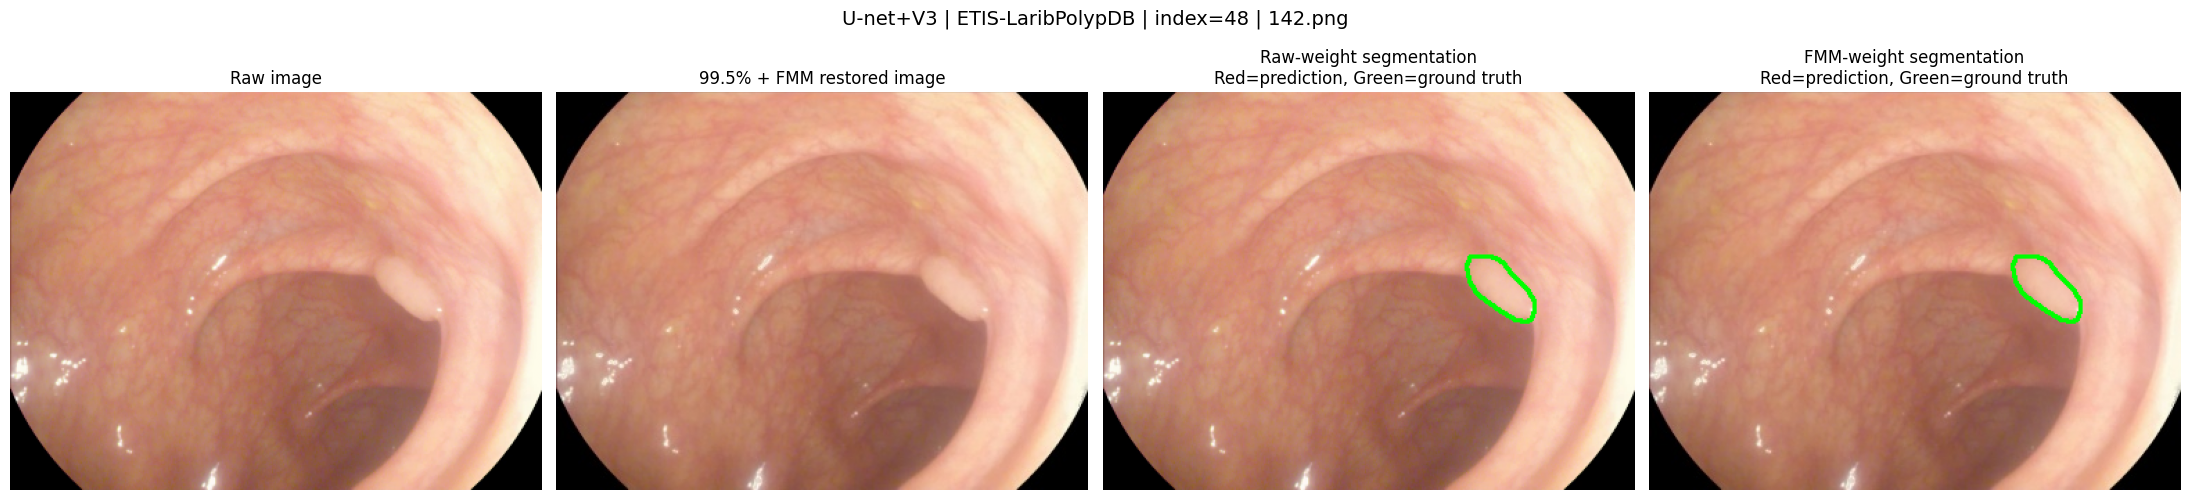

可视化使用评估缓存: 142.png


In [10]:
# =========================
# 可视化：直接使用表格评估时缓存的同一次前向结果
# =========================
import matplotlib.pyplot as plt

VIS_MASK_THRESHOLD = PREDICTION_THRESHOLD


def make_segmentation_overlay(image_rgb, prediction, ground_truth):
    """预测区域显示为红色，真实Mask边界显示为绿色。"""
    canvas = np.clip(image_rgb * 255.0, 0, 255).astype(np.uint8).copy()
    predicted_mask = np.asarray(prediction).squeeze() >= VIS_MASK_THRESHOLD
    ground_truth_mask = (np.asarray(ground_truth).squeeze() >= 0.5).astype(np.uint8)

    red = np.array([255, 0, 0], dtype=np.float32)
    canvas[predicted_mask] = (
        0.55 * canvas[predicted_mask].astype(np.float32) + 0.45 * red
    ).astype(np.uint8)

    contours, _ = cv2.findContours(
        ground_truth_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    cv2.drawContours(canvas, contours, -1, (0, 255, 0), 2)
    return canvas


def visualize_raw_vs_fmm():
    required = {"raw", "fmm"}
    if set(VISUALIZATION_CACHE) != required:
        raise RuntimeError("可视化缓存不完整，请先运行上方完整评估单元")

    raw_item = VISUALIZATION_CACHE["raw"]
    fmm_item = VISUALIZATION_CACHE["fmm"]
    if raw_item["name"] != fmm_item["name"]:
        raise RuntimeError("Raw与FMM可视化缓存对应的文件名不一致")

    raw_image = raw_item["image"]
    fmm_image = fmm_item["image"]
    ground_truth = raw_item["mask"]
    raw_prediction = raw_item["prediction"]
    fmm_prediction = fmm_item["prediction"]

    raw_overlay = make_segmentation_overlay(raw_image, raw_prediction, ground_truth)
    fmm_overlay = make_segmentation_overlay(fmm_image, fmm_prediction, ground_truth)

    figure, axes = plt.subplots(1, 4, figsize=(22, 5.5))
    panels = [
        (raw_image, "Raw image"),
        (fmm_image, "99.5% + FMM restored image"),
        (raw_overlay, "Raw-weight segmentation\nRed=prediction, Green=ground truth"),
        (fmm_overlay, "FMM-weight segmentation\nRed=prediction, Green=ground truth"),
    ]
    for axis, (panel, title) in zip(axes, panels):
        axis.imshow(panel)
        axis.set_title(title)
        axis.axis("off")

    figure.suptitle(
        f"{MODEL_NAME} | {VIS_DATASET} | index={VIS_SAMPLE_INDEX} | {raw_item['name']}",
        fontsize=14,
    )
    plt.tight_layout()
    plt.show()
    print("可视化使用评估缓存:", raw_item["name"])


visualize_raw_vs_fmm()
